In [1]:
import requests
import time
import json
import pandas as pd
import matplotlib.pyplot as plt
from urllib.robotparser import RobotFileParser

HEADERS = {
    "User-Agent": "WebDataScience/1.0 (INFO 4617; kevin.derderian@colorado.edu)"
}

URL = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/env_wasmun"

In [5]:
# chapter 2 checking robots.txt
response = requests.get("https://ec.europa.eu/robots.txt", headers=HEADERS)
print(response.status_code)

rp = RobotFileParser()
rp.parse(response.text.splitlines())
print(rp.can_fetch("*", URL))

delay = rp.crawl_delay("*")
wait = delay if delay is not None else 1.0
print(wait)

200
True
1.0


In [9]:
# Requesting Denmark due to its highly advanced implementations in WTE
response = requests.get(URL, params={"geo": "DK"}, headers=HEADERS)
print(response.status_code)
data = response.json()

print(data.keys())
print(data["dimension"].keys())
print(data["dimension"]["wst_oper"]["category"]["label"])   # treatment types
print(data["dimension"]["unit"]["category"]["label"])       # units
print(data["dimension"]["time"]["category"]["index"])       # years

200
dict_keys(['version', 'class', 'label', 'source', 'updated', 'value', 'status', 'id', 'size', 'dimension', 'extension'])
dict_keys(['freq', 'wst_oper', 'unit', 'geo', 'time'])
{'GEN': 'Waste generated', 'TRT': 'Waste treatment', 'DSP_I_RCV_E': 'Disposal - incineration (D10) and recovery - energy recovery (R1)', 'DSP_L_OTH': 'Disposal - landfill and other (D1-D7, D12)', 'DSP_I': 'Disposal - incineration (D10)', 'RCV_E': 'Recovery - energy recovery (R1)', 'RCY': 'Recycling', 'RCY_M': 'Recycling - material', 'RCY_C_D': 'Recycling - composting and digestion', 'PRP_REU': 'Preparing for reuse'}
{'KG_HAB': 'Kilograms per capita', 'THS_T': 'Thousand tonnes'}
{'1995': 0, '1996': 1, '1997': 2, '1998': 3, '1999': 4, '2000': 5, '2001': 6, '2002': 7, '2003': 8, '2004': 9, '2005': 10, '2006': 11, '2007': 12, '2008': 13, '2009': 14, '2010': 15, '2011': 16, '2012': 17, '2013': 18, '2014': 19, '2015': 20, '2016': 21, '2017': 22, '2018': 23, '2019': 24, '2020': 25, '2021': 26, '2022': 27, '2023': 28

In [25]:
COUNTRIES = ["AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "EL", "HU", "IE",
             "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"]  # EU-27 (Greece is "EL")

OPERATIONS = [
    "GEN",        # Waste generated (the total each share is divided by)
    "DSP_L_OTH",  # Landfill and other disposal
    "RCV_E",      # Energy recovery (R1): this is waste-to-energy
    "DSP_I",      # Incineration WITHOUT energy recovery (D10)
    "RCY",        # Recycling, total
    "RCY_M",      # material
    "RCY_C_D",    # composting and digestion
]

UNIT = "KG_HAB"   # Kilograms per capita

In [19]:
# repectfully collecting data
def responsible_get(url, params=None, headers=HEADERS, delay=wait):
    try:
        response = requests.get(url, params=params, headers=headers, timeout=30)
        response.raise_for_status()
        time.sleep(delay)
        return response
    except requests.exceptions.RequestException as e:
        print(f"Request failed: {e}")
        time.sleep(delay)
        return None

raw = {}
for geo in COUNTRIES:
    for op in OPERATIONS:
        params = {"geo": geo, "wst_oper": op, "unit": UNIT}
        r = responsible_get(URL, params=params)
        if r:
            raw[f"{geo}_{op}"] = r.json()
    print(geo, "done")

# Save the raw responses so you never have to download them again
with open("eurostat_env_wasmun_raw.json", "w") as f:
    json.dump(raw, f)

print(len(raw), "responses saved")

AT done
BE done
BG done
HR done
CY done
CZ done
DK done
EE done
FI done
FR done
DE done
EL done
HU done
IE done
IT done
LV done
LT done
LU done
MT done
NL done
PL done
PT done
RO done
SK done
SI done
ES done
SE done
189 responses saved


In [21]:
# turning data into Dataframe
records = []
for key, data in raw.items():
    geo, op = key.split("_", 1)
    time_index = data["dimension"]["time"]["category"]["index"]   # {"2005": 0, "2006": 1, ...}
    values = data.get("value", {})
    for year, pos in time_index.items():
        records.append({
            "geo": geo,
            "wst_oper": op,
            "year": int(year),
            "kg_per_person": values.get(str(pos))
        })

df = pd.DataFrame(records)
df = df[(df["year"] >= 2005) & (df["year"] <= 2023)]
print(df.shape)
print(df.head())

df.to_csv("eurostat_waste_2005_2023.csv", index=False)

(3591, 4)
   geo wst_oper  year  kg_per_person
10  AT      GEN  2005          575.0
11  AT      GEN  2006          597.0
12  AT      GEN  2007          597.0
13  AT      GEN  2008          600.0
14  AT      GEN  2009          590.0


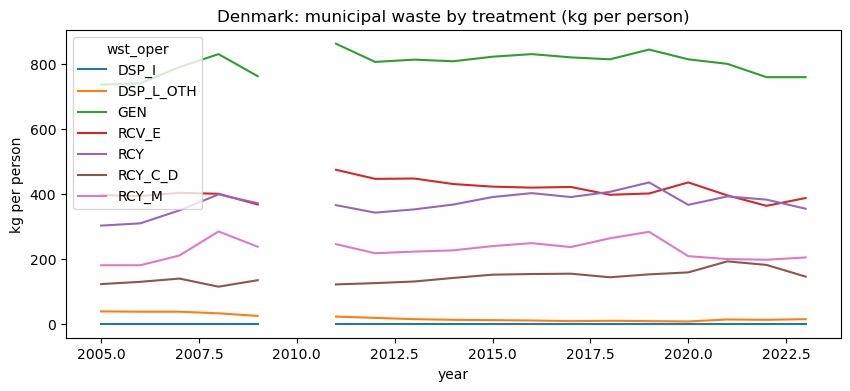

In [23]:
dk = df[df["geo"] == "DK"].pivot(index="year", columns="wst_oper", values="kg_per_person")
dk.plot(figsize=(10, 4), title="Denmark: municipal waste by treatment (kg per person)")
plt.ylabel("kg per person")
plt.show()

In [31]:
import os
print(os.getcwd())

C:\Users\Kevin\Dropbox


In [33]:
print(len(raw))          
print(list(raw.keys())[:10])   

189
['AT_GEN', 'AT_DSP_L_OTH', 'AT_RCV_E', 'AT_DSP_I', 'AT_RCY', 'AT_RCY_M', 'AT_RCY_C_D', 'BE_GEN', 'BE_DSP_L_OTH', 'BE_RCV_E']


In [35]:
for geo in COUNTRIES:
    for op in OPERATIONS:
        key = f"{geo}_{op}"
        if key in raw:
            continue
        params = {"geo": geo, "wst_oper": op, "unit": UNIT}
        r = responsible_get(URL, params=params)
        if r:
            raw[key] = r.json()
    with open("eurostat_env_wasmun_raw.json", "w") as f:
        json.dump(raw, f)            # save after every country
    print(geo, "done,", len(raw), "saved")

AT done, 189 saved
BE done, 189 saved
BG done, 189 saved
HR done, 189 saved
CY done, 189 saved
CZ done, 189 saved
DK done, 189 saved
EE done, 189 saved
FI done, 189 saved
FR done, 189 saved
DE done, 189 saved
EL done, 189 saved
HU done, 189 saved
IE done, 189 saved
IT done, 189 saved
LV done, 189 saved
LT done, 189 saved
LU done, 189 saved
MT done, 189 saved
NL done, 189 saved
PL done, 189 saved
PT done, 189 saved
RO done, 189 saved
SK done, 189 saved
SI done, 189 saved
ES done, 189 saved
SE done, 189 saved
